# Прогноз доходности Bitcoin через 4 часа

CatBoost на 27 признаках из минутных OHLCV BTC/USDT spot. Прогноз формируется каждый час после закрытия часовой свечи. Целевая переменная — изменение close за следующие 4 часа, выраженное в процентах.

Используется файл `data/BTCUSDT_spot_1m_5y.csv`. Ноутбук запускается из папки `eda`. Для запуска нужны pandas, pyarrow, catboost, scikit-learn и matplotlib. Все даты указаны в UTC.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from catboost import CatBoostRegressor
from sklearn.metrics import mean_absolute_error

## Данные и часовые свечи

Метка исходной свечи обозначает начало минуты. Часовая свеча получает время своего закрытия. Пропущенные минуты сохраняются в сетке, неполные часы исключаются из расчёта признаков.

In [2]:
data = pd.read_csv('data/BTCUSDT_spot_1m_5y.csv', engine='pyarrow')
data['datetime_utc'] = pd.to_datetime(data['datetime_utc'], utc=True)
minutes = data.set_index('datetime_utc').sort_index().asfreq('min')

hourly = minutes.resample('h', label='right', closed='left').agg({
    'open': 'first', 'high': 'max', 'low': 'min', 'close': 'last', 'volume_base': 'sum'
})
minute_count = minutes['close'].resample('h', label='right', closed='left').count()
hourly = hourly.where(minute_count.eq(60))

## Признаки

| Группа | Окна, часы | Количество |
|---|---|---:|
| Прошлая доходность | 1, 4, 12, 24, 72, 168, 336 | 7 |
| Стандартное отклонение часовых доходностей | 4, 12, 24, 72, 168, 336 | 6 |
| Отклонение close от скользящей средней | 4, 12, 24, 72, 168, 336 | 6 |
| Отношение объёма часа к среднему объёму предыдущих часов | 4, 24, 72, 168, 336 | 5 |
| Размах, тело свечи и положение close внутри её диапазона | Текущий завершённый час | 3 |

Все признаки используют информацию, доступную к моменту прогноза.

In [3]:
features = pd.DataFrame(index=hourly.index)
for window in [1, 4, 12, 24]:
    features[f'return_{window}h'] = hourly['close'].pct_change(window, fill_method=None)
for window in [4, 12, 24]:
    features[f'volatility_{window}h'] = features['return_1h'].rolling(window).std()
    features[f'ma_gap_{window}h'] = hourly['close'] / hourly['close'].rolling(window).mean() - 1
for window in [4, 24]:
    past_volume = hourly['volume_base'].shift(1).rolling(window).mean()
    features[f'volume_ratio_{window}h'] = hourly['volume_base'] / past_volume.replace(0, float('nan'))

features['range'] = (hourly['high'] - hourly['low']) / hourly['close']
features['body'] = hourly['close'] / hourly['open'] - 1
features['close_position'] = ((hourly['close'] - hourly['low']) /
                              (hourly['high'] - hourly['low']).replace(0, float('nan'))).fillna(0.5)

for window in [72, 168, 336]:
    features[f'return_{window}h'] = hourly['close'].pct_change(window, fill_method=None)
    features[f'volatility_{window}h'] = features['return_1h'].rolling(window).std()
    features[f'ma_gap_{window}h'] = hourly['close'] / hourly['close'].rolling(window).mean() - 1
    past_volume = hourly['volume_base'].shift(1).rolling(window).mean()
    features[f'volume_ratio_{window}h'] = hourly['volume_base'] / past_volume.replace(0, float('nan'))

## Цель и временные периоды

Модель предсказывает $100(C_{t+4h}/C_t-1)$. Нулевой прогноз означает, что будущая цена равна текущей. MAE измеряется в процентных пунктах доходности.

Для воспроизведения предыдущего эксперимента сохраняем его общую выборку: исключаем часы с пропущенными целями на любом из восьми ранее исследованных горизонтов. При обучении используем только цель 4 часа. Общий зазор на границах периодов составляет 6 часов.

Месячная валидация идёт с мая 2025 по апрель 2026. Перед каждым фолдом обучение расширяется всей доступной прошлой историей. Финальную модель обучаем на истории до мая 2026 и оцениваем на мае–октябре 2026.

In [4]:
close = minutes['close'].set_axis(minutes.index + pd.Timedelta(minutes=1))
horizons = ['1min', '5min', '15min', '30min', '1h', '2h', '4h', '6h']
targets = pd.DataFrame({
    horizon: close.reindex(features.index + pd.Timedelta(horizon)).to_numpy() / hourly['close'] - 1
    for horizon in horizons
})
dataset = features.join(targets).dropna()
columns = features.columns

validation_start = pd.Timestamp('2025-05-01', tz='UTC')
test_start = pd.Timestamp('2026-05-01', tz='UTC')
test_end = pd.Timestamp('2026-11-01', tz='UTC')
gap = pd.Timedelta(hours=6)

train = dataset.loc[dataset.index + gap < test_start]
test = dataset.loc[(dataset.index >= test_start) & (dataset.index + gap < test_end)]
display(pd.DataFrame({
    'Обучение': [train.index.min(), train.index.max(), len(train)],
    'Тест': [test.index.min(), test.index.max(), len(test)]
}, index=['Начало UTC', 'Конец UTC', 'Часов']).T)

,Начало UTC,Конец UTC,Часов
Обучение,2021-11-16 10:00:00+00:00,2026-04-30 17:00:00+00:00,38688
Тест,2026-05-01 00:00:00+00:00,2026-10-31 17:00:00+00:00,4410


## Модель и временная валидация

Конфигурация зафиксирована по предыдущим экспериментам: 200 деревьев глубины 5, learning rate 0,03, L2-регуляризация 10 и функция потерь MAE. Ниже оцениваем её на 12 месячных фолдах. Подбор параметров повторно не проводится.

In [5]:
params = dict(
    iterations=200, depth=5, learning_rate=0.03, l2_leaf_reg=10,
    loss_function='MAE', random_seed=42, thread_count=4,
    verbose=False, allow_writing_files=False
)

cv_rows = []
months = pd.date_range(validation_start, test_start, freq='MS', inclusive='left')
for month in months:
    fit = train.loc[train.index + gap < month]
    valid = train.loc[(train.index >= month) & (train.index + gap < month + pd.offsets.MonthBegin(1))]
    model = CatBoostRegressor(**params)
    model.fit(fit[columns], fit['4h'] * 100)
    predicted = model.predict(valid[columns])
    cv_rows.append({
        'Месяц': month.strftime('%Y-%m'), 'Часов': len(valid),
        'MAE CatBoost': mean_absolute_error(valid['4h'] * 100, predicted),
        'MAE нуля': valid['4h'].abs().mean() * 100
    })

cv = pd.DataFrame(cv_rows).set_index('Месяц')
cv['Улучшение, %'] = 100 * (1 - cv['MAE CatBoost'] / cv['MAE нуля'])
display(cv.round(6))

,Часов,MAE CatBoost,MAE нуля,"Улучшение, %"
Месяц,,,,
2025-05,738,0.547248,0.550541,0.598125
2025-06,714,0.488834,0.493178,0.880700
2025-07,738,0.434822,0.436498,0.383999
2025-08,738,0.470482,0.468618,-0.397727
2025-09,714,0.398840,0.401098,0.562997
2025-10,738,0.664697,0.664210,-0.073316
2025-11,714,0.760470,0.758162,-0.304512
2025-12,738,0.619123,0.622868,0.601275
2026-01,738,0.539878,0.539956,0.014446


## Финальное обучение и тест

Переобучаем модель на всей обучающей выборке. Во время шестимесячного теста её веса фиксированы. Средняя валидационная MAE ниже считается как среднее по 12 месяцам, тестовая MAE — по всем тестовым часам.

In [6]:
model = CatBoostRegressor(**params)
model.fit(train[columns], train['4h'] * 100)
prediction = pd.Series(model.predict(test[columns]), index=test.index, name='Прогноз')

scores = pd.DataFrame({
    'Валидация': {
        'MAE CatBoost': cv['MAE CatBoost'].mean(), 'MAE нуля': cv['MAE нуля'].mean()
    },
    'Тест': {
        'MAE CatBoost': mean_absolute_error(test['4h'] * 100, prediction),
        'MAE нуля': test['4h'].abs().mean() * 100
    }
}).T
scores['Улучшение, %'] = 100 * (1 - scores['MAE CatBoost'] / scores['MAE нуля'])
display(scores.round(6))

,MAE CatBoost,MAE нуля,"Улучшение, %"
Валидация,0.601446,0.602635,0.197373
Тест,0.517196,0.518674,0.284938


,MAE CatBoost,MAE нуля,"Улучшение, %"
Месяц,,,
2026-05,0.438333,0.438843,0.116317
2026-06,0.741154,0.741729,0.077561
2026-07,0.485963,0.485163,-0.164799
2026-08,0.485296,0.491409,1.243988
2026-09,0.484211,0.485473,0.260005
2026-10,0.474035,0.475203,0.245648


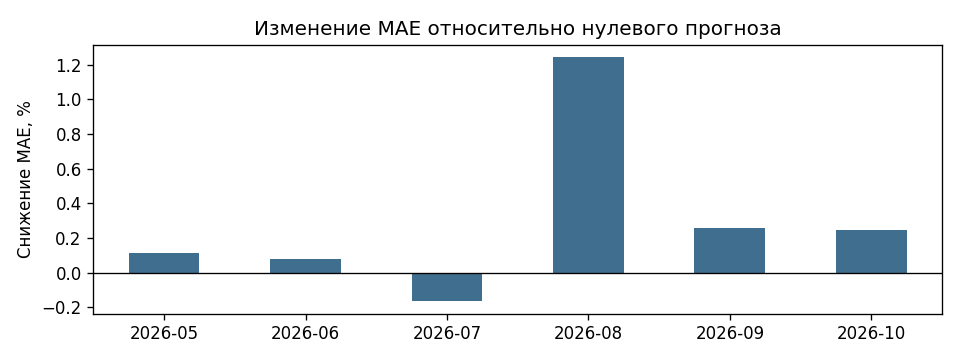

In [7]:
monthly_rows = []
for month, actual in test['4h'].groupby(test.index.strftime('%Y-%m')):
    monthly_rows.append({
        'Месяц': month,
        'MAE CatBoost': mean_absolute_error(actual * 100, prediction.loc[actual.index]),
        'MAE нуля': actual.abs().mean() * 100
    })
monthly = pd.DataFrame(monthly_rows).set_index('Месяц')
monthly['Улучшение, %'] = 100 * (1 - monthly['MAE CatBoost'] / monthly['MAE нуля'])
display(monthly.round(6))

ax = monthly['Улучшение, %'].plot.bar(figsize=(8, 3), color='#406e8e', rot=0)
ax.axhline(0, color='black', linewidth=0.8)
ax.set(title='Изменение MAE относительно нулевого прогноза', xlabel='', ylabel='Снижение MAE, %')
plt.tight_layout()
plt.show()

## Прогноз и фактическая доходность

Накладываем прогноз CatBoost и фактическое изменение цены BTC за следующие **4 часа**. Обе линии выражены в процентах и используют одну шкалу. По оси X — момент, когда был сделан прогноз.

Сначала смотрим весь тест, затем первую неделю — фиксированный участок с 1 по 7 мая 2026 года. Даты недели можно поменять в ячейке ниже.

In [8]:
comparison = pd.DataFrame()
comparison['Факт'] = test['4h'] * 100
comparison['Прогноз'] = prediction

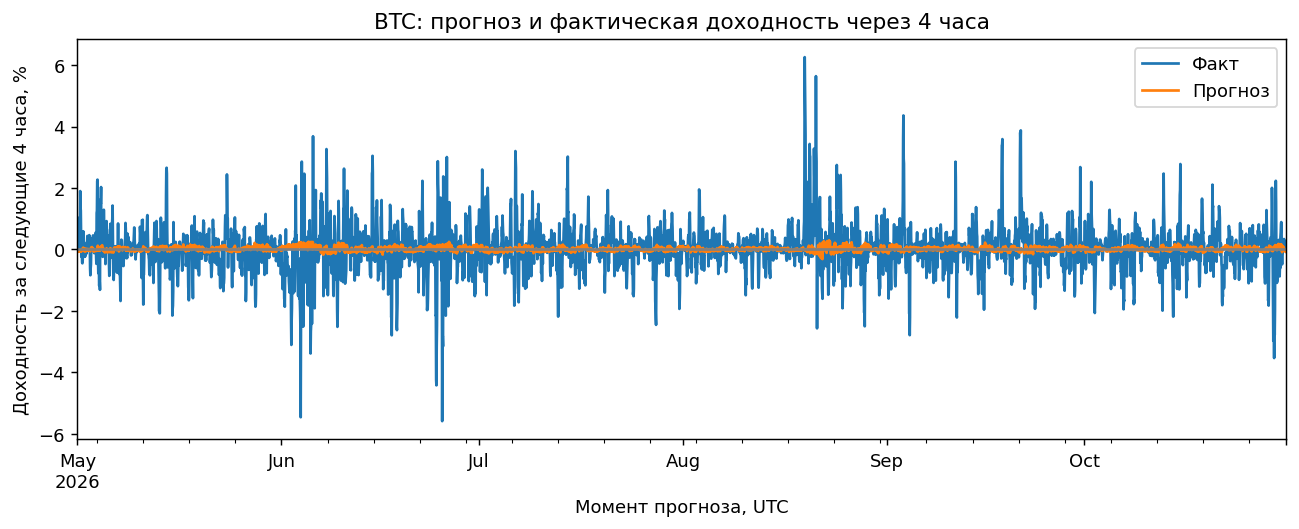

In [9]:
comparison.plot(figsize=(12, 4))
plt.title('BTC: прогноз и фактическая доходность через 4 часа')
plt.xlabel('Момент прогноза, UTC')
plt.ylabel('Доходность за следующие 4 часа, %')
plt.axhline(0, color='gray')
plt.show()

### Приближение: первая неделя теста

На коротком участке легче сравнить направление и величину изменений. Масштаб двух линий остаётся одинаковым.

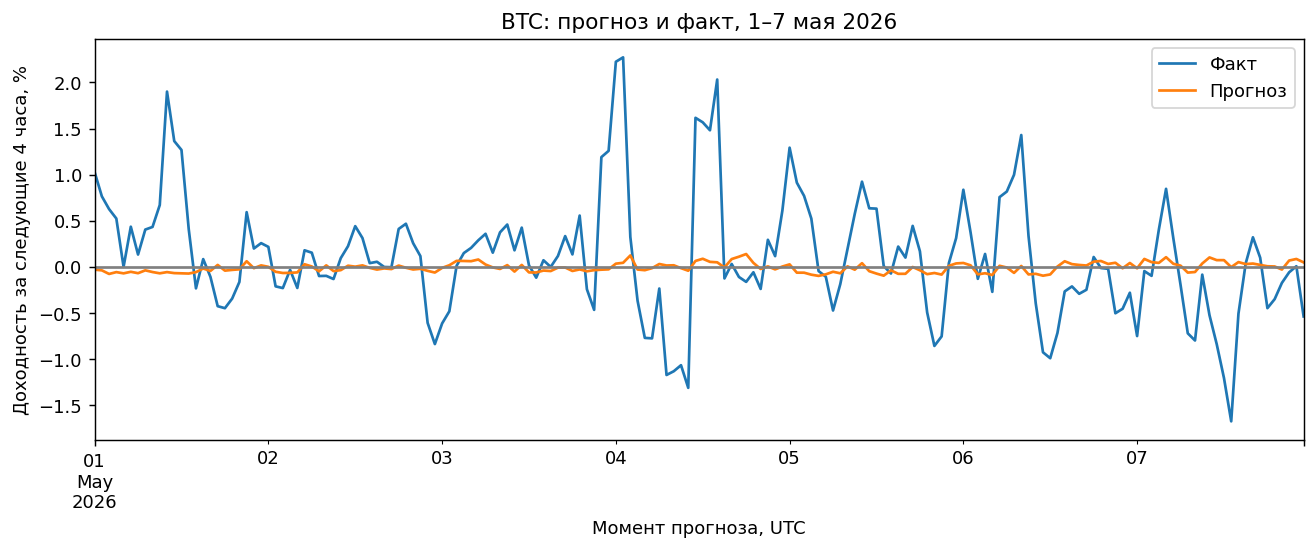

In [10]:
week = comparison.loc['2026-05-01':'2026-05-07']
week.plot(figsize=(12, 4))
plt.title('BTC: прогноз и факт, 1–7 мая 2026')
plt.xlabel('Момент прогноза, UTC')
plt.ylabel('Доходность за следующие 4 часа, %')
plt.axhline(0, color='gray')
plt.show()

### Те же прогнозы в виде цены BTC

Переводим прогноз доходности в цену: `цена сейчас × (1 + прогноз / 100)`. По оси X здесь **время целевой цены**, на 4 часа позже момента прогноза.

Для сравнения добавлена цена, известная в момент прогноза: это вариант «через 4 часа цена не изменится». Близость линий на ценовом графике нужно оценивать относительно этого простого варианта — основную часть уровня цены модель уже знает.

In [11]:
future_time = week.index + pd.Timedelta(hours=4)
current_price = hourly['close'].reindex(week.index)
predicted_price = current_price * (1 + prediction.reindex(week.index) / 100)
price_comparison = pd.DataFrame(index=future_time)
price_comparison['Фактическая цена'] = hourly['close'].reindex(future_time).to_numpy()
price_comparison['Прогноз модели'] = predicted_price.to_numpy()
price_comparison['Цена в момент прогноза'] = current_price.to_numpy()

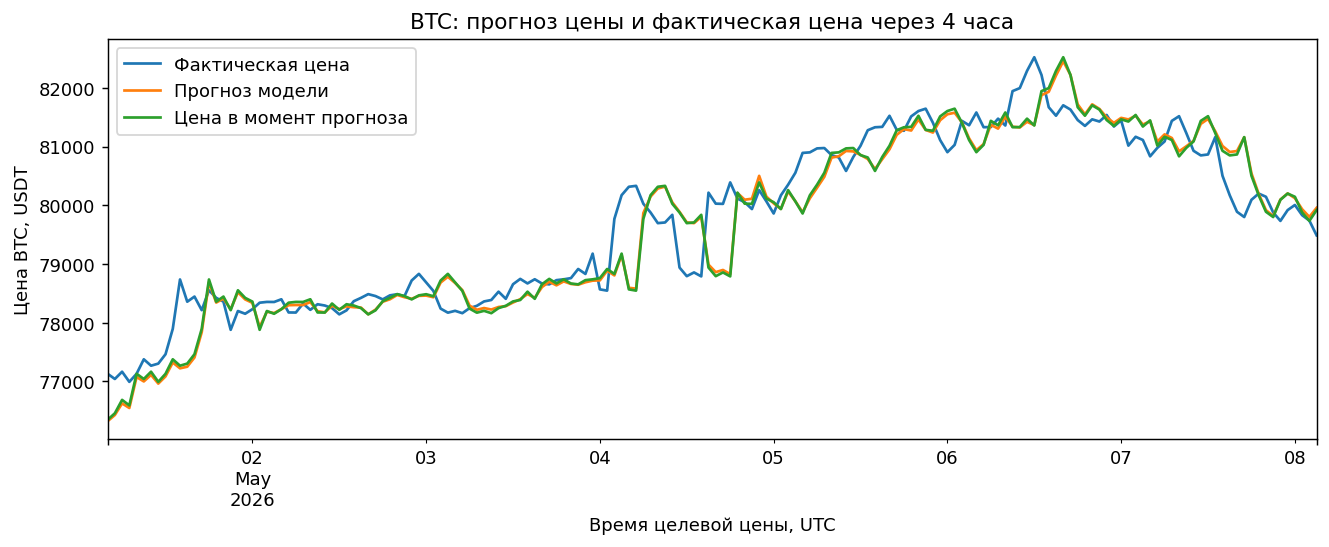

In [12]:
price_comparison.plot(figsize=(12, 4))
plt.title('BTC: прогноз цены и фактическая цена через 4 часа')
plt.xlabel('Время целевой цены, UTC')
plt.ylabel('Цена BTC, USDT')
plt.show()

## Результат

На 4410 тестовых часах MAE CatBoost составила **0.517196 п.п.**, MAE нулевого прогноза — **0.518674 п.п.**. Снижение ошибки составило **0.285%**. Выигрыш небольшой и различается по месяцам.

Конфигурация и горизонт выбраны в предыдущем исследовании, а тестовый период многократно использовался для сравнения моделей. Результат является ретроспективным и требует проверки на новом периоде.